In [108]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from typing import Any, Callable

# Generating Final Dataframe for Analysis

In [109]:
# Reading Log Returns for Each Asset and the Interest Rates for the Credit

# Stock Data
portfolio_df = pd.read_csv("_portfolio_returns.csv", index_col=["Date"], parse_dates = True).drop(columns=["EURIBOR_3M","returns_EUR_USD"])
loss_df = -portfolio_df

# Reading Rates for Credit
euribor = pd.read_csv("_portfolio_returns.csv", index_col=["Date"], parse_dates = True)[["EURIBOR_3M"]]
loan_position = (1 - (euribor / 100)) ** (1 / 365) - 1

loss_df = loss_df.loc[loan_position.index]
portfolio_df = portfolio_df.loc[loan_position.index]
# Declaring weights for portfolio construction, DON'T FORGET TO UPDAtE ONCE CREDIT IS ADDED
PORTFOLIO_WEIGHTS= np.array([0.15, 0.2, 0.15, 0.15, 0.15, 0.2])    # If we short something we can get more cash to invest
PORTFOLIO_WEIGHTS = np.array((PORTFOLIO_WEIGHTS / (4 / 3)).tolist() + [.25])

In [110]:
def credit_risk(credit, short = True):
    """
    Function that calculates the loss at each time t of a loan
    """
    # We define the end time
    credit = 1 + credit / 100

    # Translate annual yield to daily yield
    credit = credit ** (1 / 365) - 1
    T = len(credit)
    t = np.arange(T).reshape((T, 1))

    # take the difference in yield
    x = credit.diff().fillna(0)

    # y is defines as the yield, i.e. the credit
    y = credit
    p = np.exp(-(T - t) * y)
    loss = p * (y - (T - t) * x) * ((-1) ** short)
    val = np.exp(np.cumsum(loss))
    # Slice the data to only have the dates in which the credit changed and fo a resample with a forward fill
    # .loc[slice].resample('1d').last().ffill()
    return loss, val

### Credit Risk Calculation

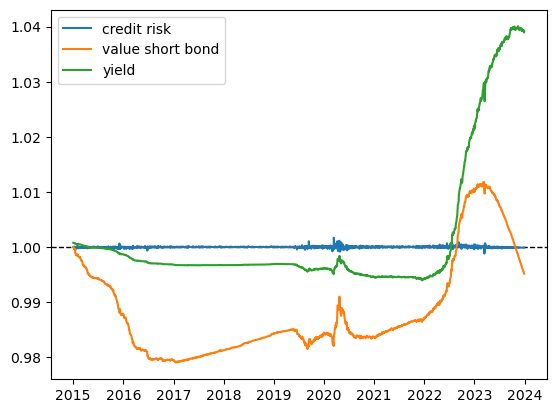

In [111]:
credit = euribor
loss, val = credit_risk(credit)
plt.axhline(1, lw = 1, c = 'black', ls = '--')
plt.plot(1 + loss, label = 'credit risk')
plt.plot(val, label = 'value short bond')
plt.plot(1 + credit / 100, label = 'yield')
plt.legend()
plt.show()

In [112]:
loss_df['loan'] = loss
portfolio_df['loan'] = -loss

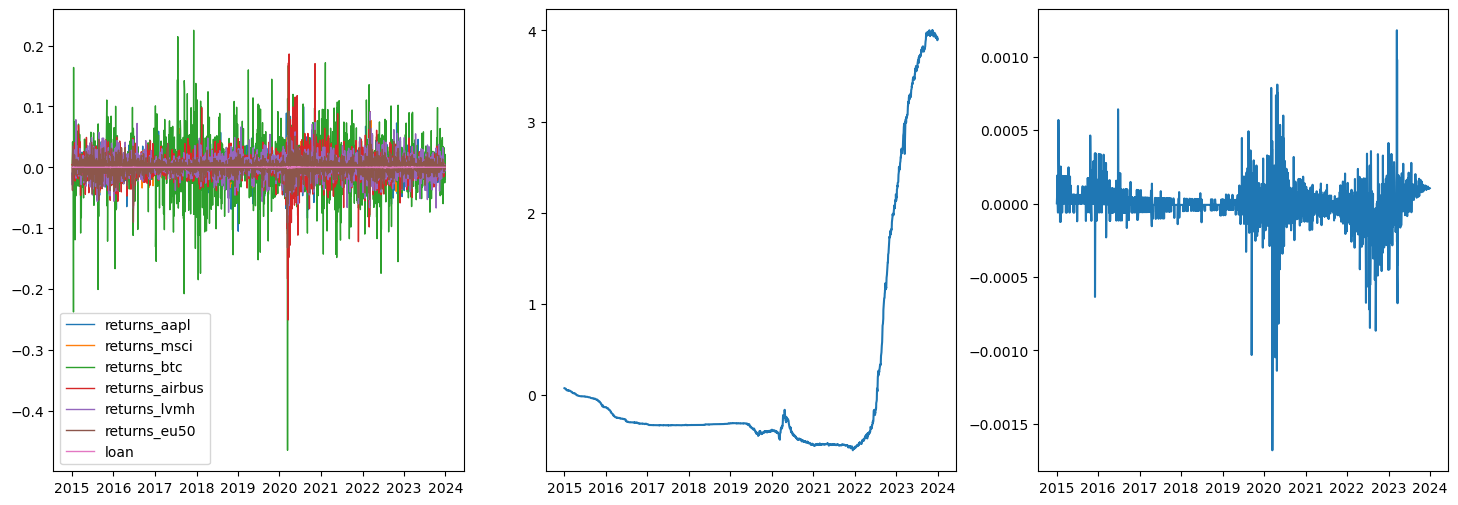

In [113]:
fig, axs = plt.subplots(1,3, figsize = (18, 6))
axs[0].plot(portfolio_df, label = portfolio_df.columns, lw = 1)
axs[1].plot(euribor)
axs[2].plot(portfolio_df.loan)
axs[0].legend()
plt.show()

In [114]:
from typing import Callable, Any

def LossDist(_) -> Any : return -_

def PortRet(*, data: pd.DataFrame, weights: np.array) -> pd.DataFrame:

    assert np.sum(weights) == 1
    return data @ weights

In [115]:
T = len(portfolio_df)
t = np.arange(T).reshape((T,1))
X_yield = euribor.diff()

_yield = (1 + euribor / 100) ** (1 / 365) - 1
derivative_time = -np.exp(-(T - t) * _yield) * _yield

<Axes: xlabel='Date'>

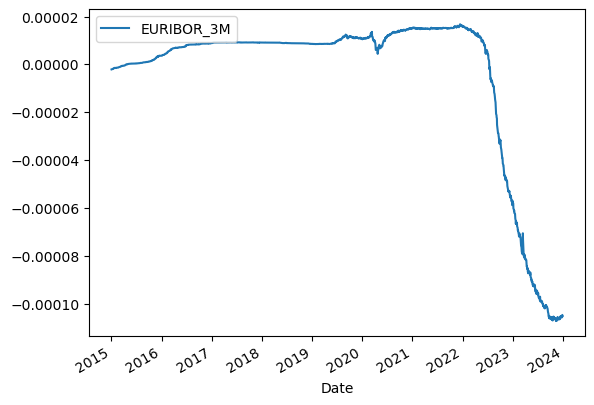

In [116]:
derivative_time.plot()

Include $V\lambda\exp(Z(t)-Z(0))=V\lambda\exp(\log S(t)/S(0))=V\lambda S(t)/S(0)$

In [117]:
def loss_operator(log_returns: pd.DataFrame, yield_curve: pd.DataFrame, weights: Any, value: float = 1.0):
    """
    The first order tayler expansion of the loss operator L
    """

    daily_yield_curve = (1 + yield_curve / 100) ** (1 / 365) - 1
    T = len(log_returns)
    t = np.arange(T).reshape((T,1))
    X_yield = daily_yield_curve.diff()
    derivative_time = -np.exp(-(T - t) * daily_yield_curve) * daily_yield_curve


## VaR ES calculation with All the Methods

In [118]:
def Var_Cov_VaR(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = pf_vol * dist(alpha, **kwargs)
    return portfolio_VaR.dropna()

def Var_Cov_ES(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    alpha = 1 - alpha
    match dist:
        case stats.norm:
            q: float = stats.norm.isf(alpha)
            p: float = stats.norm.pdf(q)
            return Vol * p / (alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.isf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return Vol * ((df + (q ** 2)) / (df - 1)) * p / (alpha)
        case _:
            raise NotImplementedError() 

In [119]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T =len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        sig[t+1] = omega + alpha *  (x[t]**2) + beta * sig[t]

    return sig ** .5

def GARCH_portfolio_variance(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr()
    n: int = CM.shape[0]
    W = weights.reshape((n, 1)) * weights.reshape((1,7))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .05, .93
        omega = np.var(x) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
            
    vol = []
    
    Sigm = vol_df.values
    for row in Sigm:
        # Variance as outer product of the weights with the covariance
        vol.append(row @ CMU @ row)

    return np.array(vol) ** .5

def GARCH_VaR(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)

In [120]:
def devol(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    pf_loss = PortRet(data = data, weights = port_weights)
    
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    return pf_loss / portfolio_VaR.Vol

In [121]:
window_size = 258

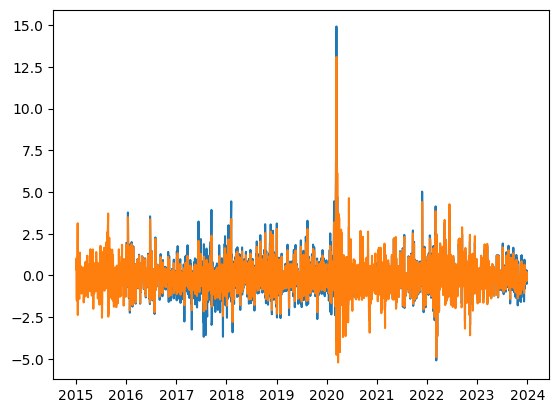

In [122]:
plt.plot(devol(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.norm.ppf))
plt.plot(PortRet(data = loss_df, weights = PORTFOLIO_WEIGHTS) * 100)

In [123]:
VaR_HS_normal = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4 = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5 = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6 = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.t.ppf, df = 6)

In [124]:
# Implemented in the next section

# methods = [(stats.norm, {}), (stats.t, 4), (stats.t, 5), (stats.t, 6)]

# plt.figure(figsize=(16,16))
# i=1
# plt.title(portfolio_df.columns[i])
# for j, (d, a) in enumerate(methods):
#     sm.qqplot(portfolio[:,i], dist=d, distargs=(a,), line="q",
#                 ax=plt.subplot(2,2,j))
#     j += 1
# plt.show()

In [125]:
ES_HS_normal = Var_Cov_ES(VaR_HS_normal.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4 = Var_Cov_ES(VaR_HS_student4.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5 = Var_Cov_ES(VaR_HS_student5.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6 = Var_Cov_ES(VaR_HS_student6.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = loss_df[window_size:]

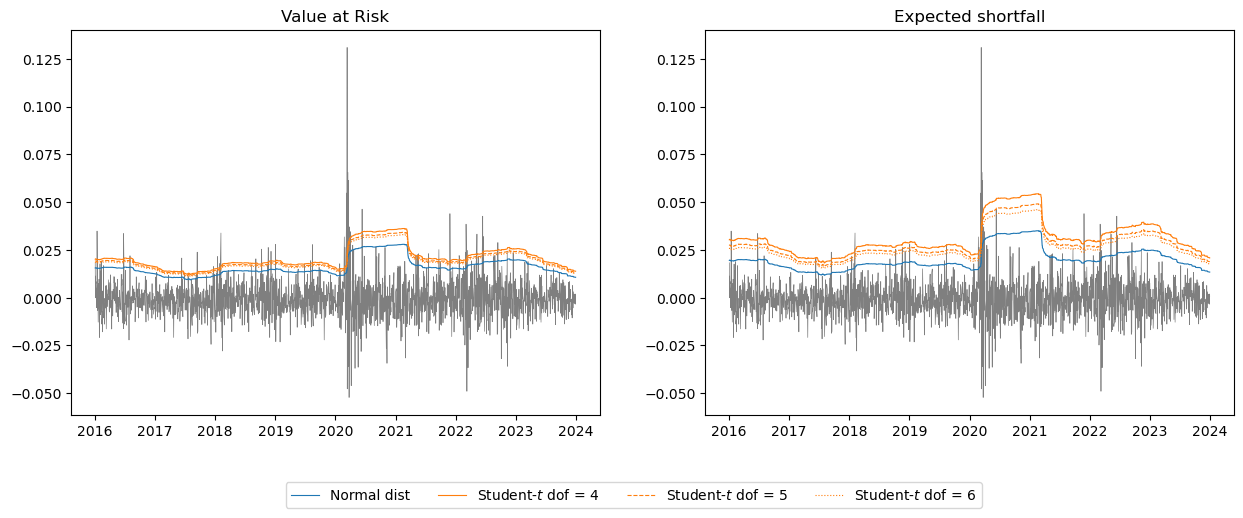

In [126]:
fig, axs = plt.subplots(1, 2, figsize = (15, 15 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[1].plot(ES_HS_normal, label = 'Normal dist', lw = .8)
axs[1].plot(ES_HS_student4, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1].plot(ES_HS_student5, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1].plot(ES_HS_student6, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[0].plot(VaR_HS_normal.VaR, label = 'Normal dist', lw = .8)
axs[0].plot(VaR_HS_student4.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0].plot(VaR_HS_student5.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0].plot(VaR_HS_student6.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()

In [127]:
def Historic_Simulation(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, **kwargs) -> float:
    """
    Calculate VaR and ES using historic simulation
    """

    # Calculate the volatility
    portfolio_returns = PortRet(data = data, weights = port_weights)
    df = pd.DataFrame([], index = data.index, columns = ['VaR'])
    VaR = portfolio_returns.rolling(window = window_size).quantile(alpha)
    ES  = [np.nan] * window_size
    for k in range(window_size, len(data)):
        _ = portfolio_returns.iloc[k - window_size: k]
        _ = _[_ >= VaR.iloc[k]]
        ES.append(np.mean(_))
        
    df['VaR'] = VaR
    df['ES'] = ES
    return df.dropna()

def filtered_HS(returns, weights, _alpha, window_size):
    Devol = pd.DataFrame([], index = returns.index)
    Vol = pd.DataFrame([], index = returns.index)
    for col in returns.columns:
        # Filter the volatility for each individual asset using the EWMA method
        x = returns[col]
        alpha = .05
        beta = 1 - alpha
        omega = 0
        vol = volatility(omega, alpha, beta, x)
        Vol[f'Vol {col}'] = vol
        Devol[f'Devol {col}'] = returns[col] / vol 
    # Calculate the portfolio volatility (not sure if correct)

    df = pd.DataFrame([], index = returns.index, columns = ['VaR'])

    # Define a rolling window VaR estimator
    ES  = [np.nan] * window_size
    VaR = [np.nan] * window_size
    for k in range(window_size, len(returns)):
        # Get the window over the devol object, and multiply with the predicted volatility
        D = Devol.iloc[k - window_size: k] * Vol.iloc[k].values

        # get the returns and calculate the VaR
        portfolio_returns = PortRet(data = D, weights = weights)
        VaR.append(portfolio_returns.rolling(window = window_size).quantile(_alpha).iloc[-1])
        
        _ = portfolio_returns[portfolio_returns >= VaR[k]]
        # The expected shortfall is the mean of the returns conditional on exceeding the var
        ES.append(np.mean(_))
    df['VaR'] = VaR
    df['ES'] = np.array(ES)
    return df.dropna()

In [128]:
VaR_ES_Historic_Simulation = Historic_Simulation(loss_df, window_size, PORTFOLIO_WEIGHTS, .95)

In [129]:
EWMA_HS = filtered_HS(loss_df, PORTFOLIO_WEIGHTS, .95, window_size)

In [130]:
GARCH = GARCH_portfolio_variance(loss_df_sliced, weights = PORTFOLIO_WEIGHTS)
VaR_GARCH = GARCH_VaR(GARCH, .95, stats.norm.ppf)
ES_GARCH = Var_Cov_ES(GARCH, .95, stats.norm)
ES_GARCH = pd.DataFrame(ES_GARCH, index = loss_df_sliced.index)

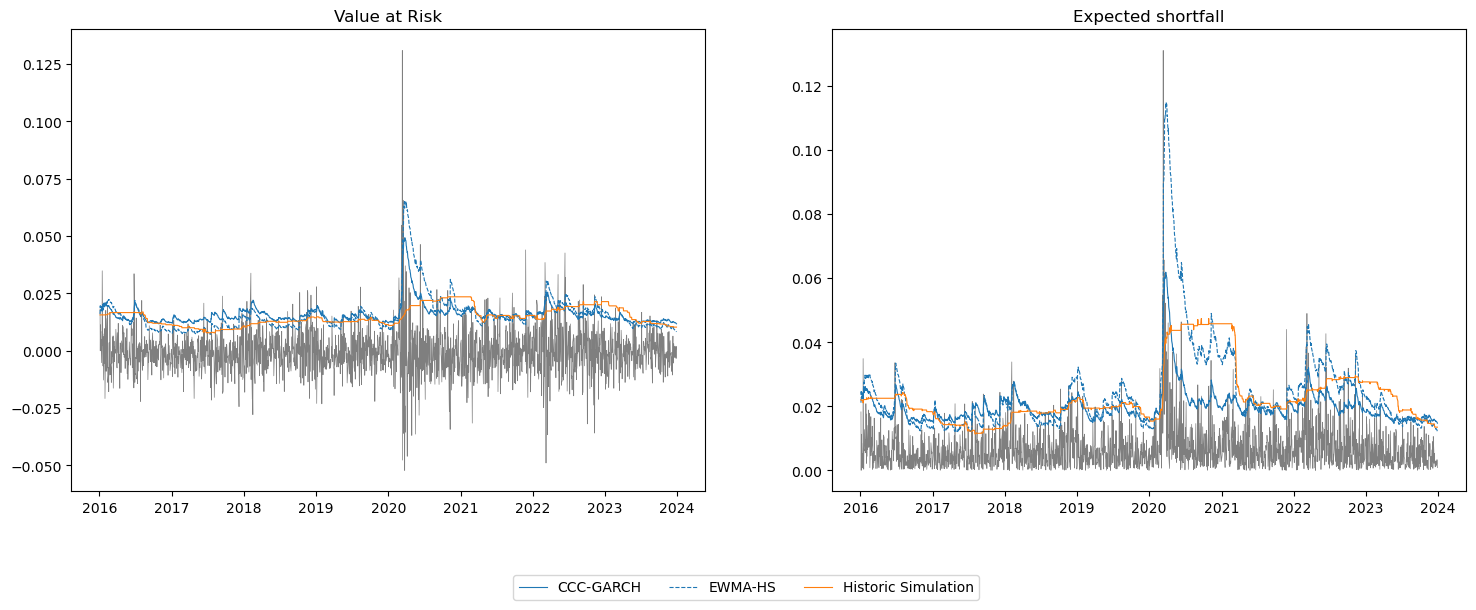

In [131]:
fig, axs = plt.subplots(1, 2, figsize = (18, 6))
# fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS).abs(), lw = .5, c = 'black', alpha = .5)
axs[1].plot(loss_df_sliced.index, ES_GARCH, label = 'CCC-GARCH', lw = .8, c = 'C0')
axs[1].plot(EWMA_HS.ES, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[1].plot(VaR_ES_Historic_Simulation.ES, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[0].plot(loss_df_sliced.index, VaR_GARCH, label = 'CCC-GARCH', c = 'C0', lw = .8)
axs[0].plot(EWMA_HS.VaR, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[0].plot(VaR_ES_Historic_Simulation.VaR, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()

# Violation analysis (Daan's)

We start with the analysis of the value at risk violations

In [132]:
def VaR_violations(loss: pd.DataFrame, VaR: object) -> ...:
    try: 
        vv = np.where(loss >= VaR, 1, 0)
        vv = pd.DataFrame(vv, index = loss.index, columns = ['violation dates'])
    except: 
        vv = np.where(loss.loc[VaR.index] >= VaR, 1, 0)
        vv = pd.DataFrame(vv, index = VaR.index, columns = ['violation dates'])
    return vv[vv['violation dates'] == 1].index, vv

In [133]:
portfolio_risk = PortRet(data = loss_df, weights = PORTFOLIO_WEIGHTS)

In [134]:
VaR_violations_normal_dates, VaR_violations_normal = VaR_violations(portfolio_risk, VaR_HS_normal.VaR)
VaR_violations_t4_dates, VaR_violations_t4 = VaR_violations(portfolio_risk, VaR_HS_student4.VaR)
VaR_violations_t5_dates, VaR_violations_t5 = VaR_violations(portfolio_risk, VaR_HS_student5.VaR)
VaR_violations_t6_dates, VaR_violations_t6 = VaR_violations(portfolio_risk, VaR_HS_student6.VaR)
VaR_violations_garch_dates, VaR_violations_garch = VaR_violations(portfolio_risk[window_size:], VaR_GARCH)
VaR_violations_ewma_dates, VaR_violations_ewma = VaR_violations(portfolio_risk[window_size:], VaR_ES_Historic_Simulation.VaR)

In [135]:
VaRS = [
    VaR_violations_normal_dates,
    VaR_violations_t4_dates, 
    VaR_violations_t5_dates,
    VaR_violations_t6_dates,
    VaR_violations_garch_dates,
    VaR_violations_ewma_dates,
]

In [136]:
portfolio_risk

Date
2015-01-02    0.003710
2015-01-05    0.010199
2015-01-06   -0.004051
2015-01-07   -0.012276
2015-01-08   -0.015049
                ...   
2023-12-22    0.001355
2023-12-26    0.001981
2023-12-27   -0.003356
2023-12-28    0.001779
2023-12-29    0.000870
Length: 2324, dtype: float64

In [137]:
years = pd.to_datetime([str(2015 + i) for i in range(10)])
years = list(zip(years[:-1], years[1:]))

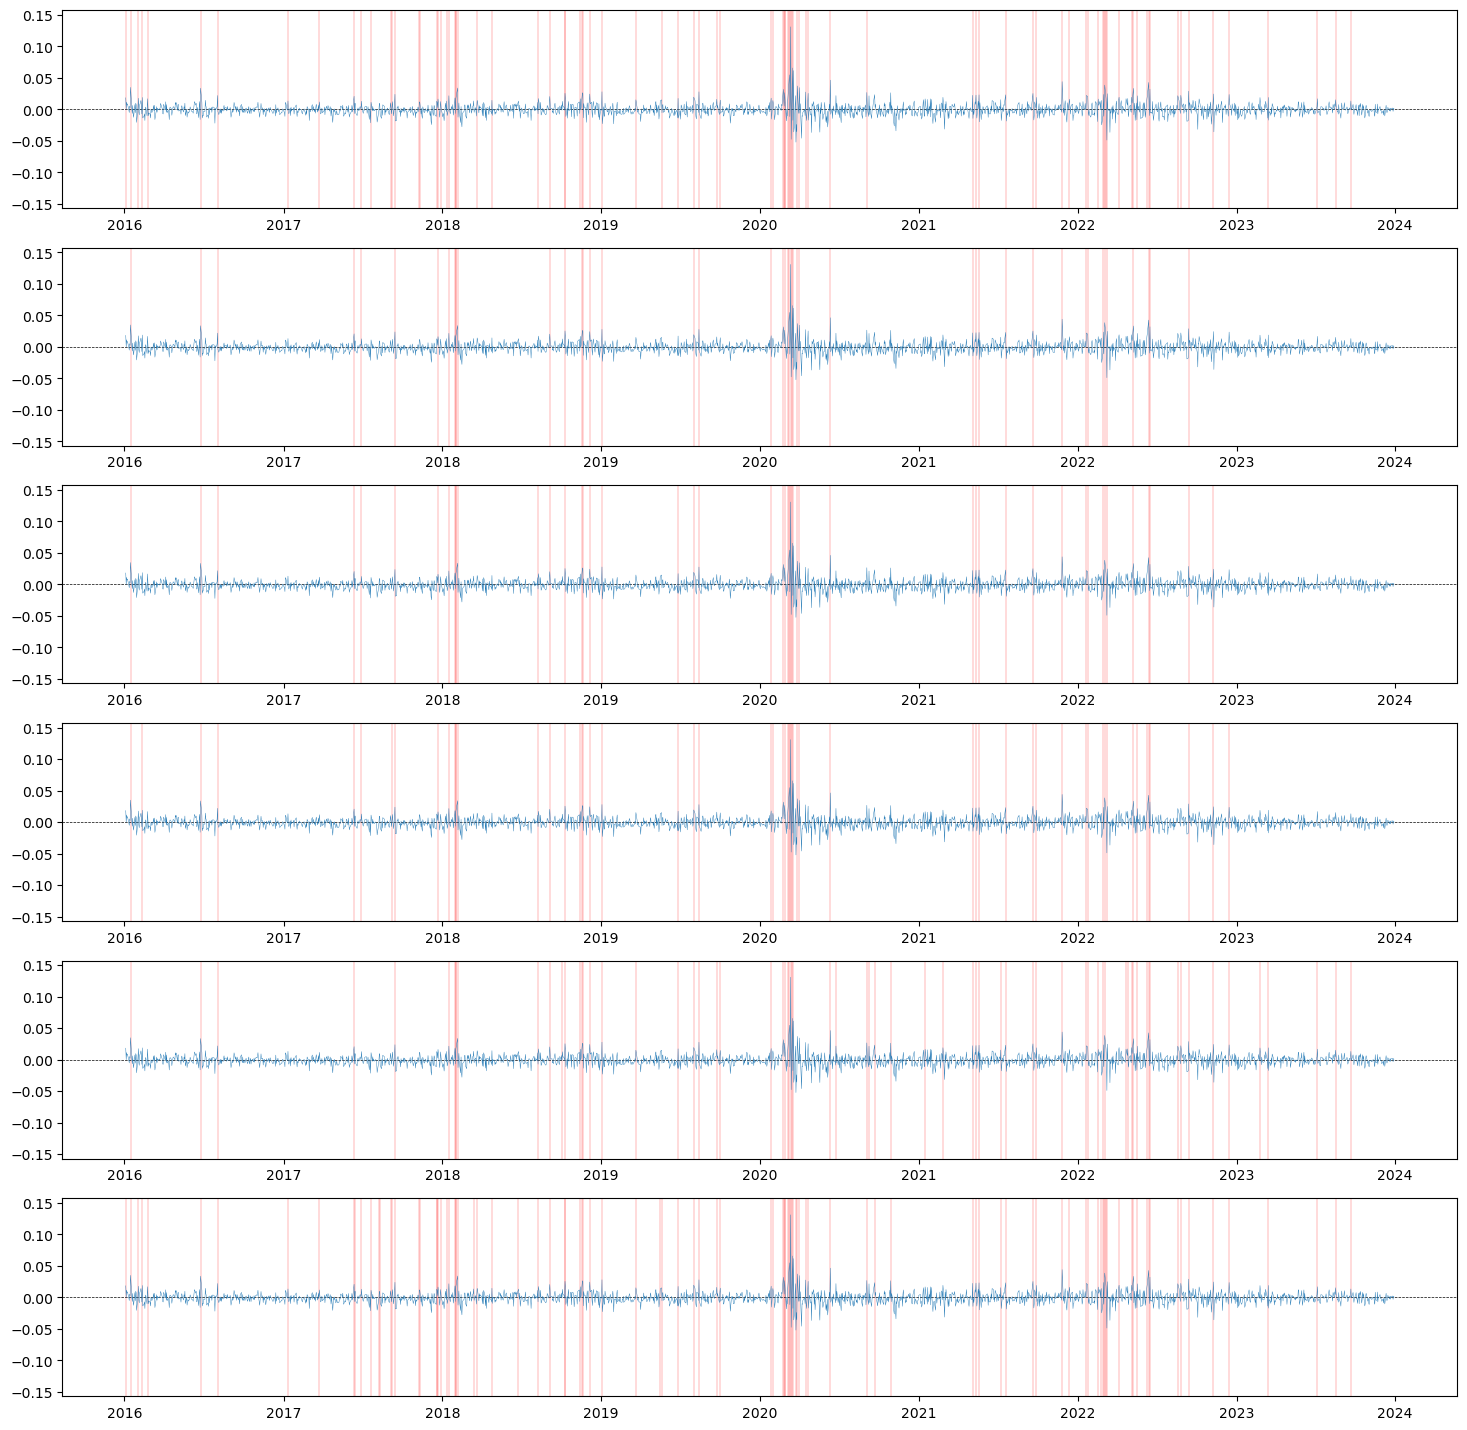

In [138]:
fig, axs = plt.subplots(len(VaRS), 1, figsize = (18, 18))
for i, y in enumerate(VaRS):
    for x in y: axs[i].axvline(x, c = 'red', lw = .2)
    sliced = portfolio_risk.loc[loss_df_sliced.index]
    m = max(sliced.abs())
    axs[i].axhline(0, c = 'black', ls = '--', lw = .5)
    axs[i].plot(sliced, lw = .3, alpha = 1) 
    axs[i].set_ylim([-1.2 * m, 1.2 * m])
plt.show()

In [139]:
# for y in VaRS:
#     fix, axs = plt.subplots(1, len(years), figsize = (18, 18 / len(years)))
#     for i, (start, end) in enumerate(years):
#         for x in y[(y >= start) & (y < end)]: axs[i].axvline(x, c = 'red', lw = .5)
#         sliced = portfolio_risk[(portfolio_risk.index < end) & (portfolio_risk.index >= start)]
#         axs[i].plot(sliced, lw = .3, alpha = 1)
#     plt.show()

In [140]:
def get_actual_ES(risk, years, ES_pred, alpha = .95):
    for start, end in years:
        sliced = risk[(risk.index < end) & (risk.index >= start)]
        VaR = sliced.quantile(alpha)
        ES = np.mean(sliced[sliced >= VaR])
        ES_act = str(np.round(ES, 4)).ljust(6, '0')
        _ = np.mean(ES_pred[(ES_pred.index < end) & (ES_pred.index > start)])
        ES_pred_sliced = str(np.round(_, 4)).ljust(6, '0')
        dis = str(np.round(100 * _ / ES, 2)).ljust(2, '0')
        print(f'Actual vs predicted ES between {start.date()} and {end.date()}: {ES_act} vs {ES_pred_sliced} ({dis}%)')

In [141]:
names = [
    (ES_HS_normal, 'normal'), (ES_HS_student4, 'student t 4'), (ES_HS_student5, 'student t 5'), (ES_HS_student6, 'student t 6'), (ES_GARCH, 'garch'), (EWMA_HS, 'ewma')
]

In [142]:
for m, n in names:
    print(n)
    get_actual_ES(portfolio_risk, years, m)
    print('')

normal
Actual vs predicted ES between 2015-01-01 and 2016-01-01: 0.0216 vs nan000 (nan%)
Actual vs predicted ES between 2016-01-01 and 2017-01-01: 0.0183 vs 0.0187 (101.96%)
Actual vs predicted ES between 2017-01-01 and 2018-01-01: 0.0140 vs 0.0133 (95.6%)
Actual vs predicted ES between 2018-01-01 and 2019-01-01: 0.0216 vs 0.0174 (80.16%)
Actual vs predicted ES between 2019-01-01 and 2020-01-01: 0.0166 vs 0.0173 (103.78%)
Actual vs predicted ES between 2020-01-01 and 2021-01-01: 0.0457 vs 0.0295 (64.44%)
Actual vs predicted ES between 2021-01-01 and 2022-01-01: 0.0214 vs 0.0231 (107.86%)
Actual vs predicted ES between 2022-01-01 and 2023-01-01: 0.0276 vs 0.0226 (81.99%)
Actual vs predicted ES between 2023-01-01 and 2024-01-01: 0.0135 vs 0.0191 (141.58%)

student t 4
Actual vs predicted ES between 2015-01-01 and 2016-01-01: 0.0216 vs nan000 (nan%)
Actual vs predicted ES between 2016-01-01 and 2017-01-01: 0.0183 vs 0.0290 (158.32%)
Actual vs predicted ES between 2017-01-01 and 2018-01-01

# Backtest (Christos's)

### QQ-Plot and Histogram of Losses on the Portfolio Level

In [143]:
# PROBABLY WRONG, it should has the distribution of L(t+1)
portfolio_weighted = loss_df.dot(PORTFOLIO_WEIGHTS)

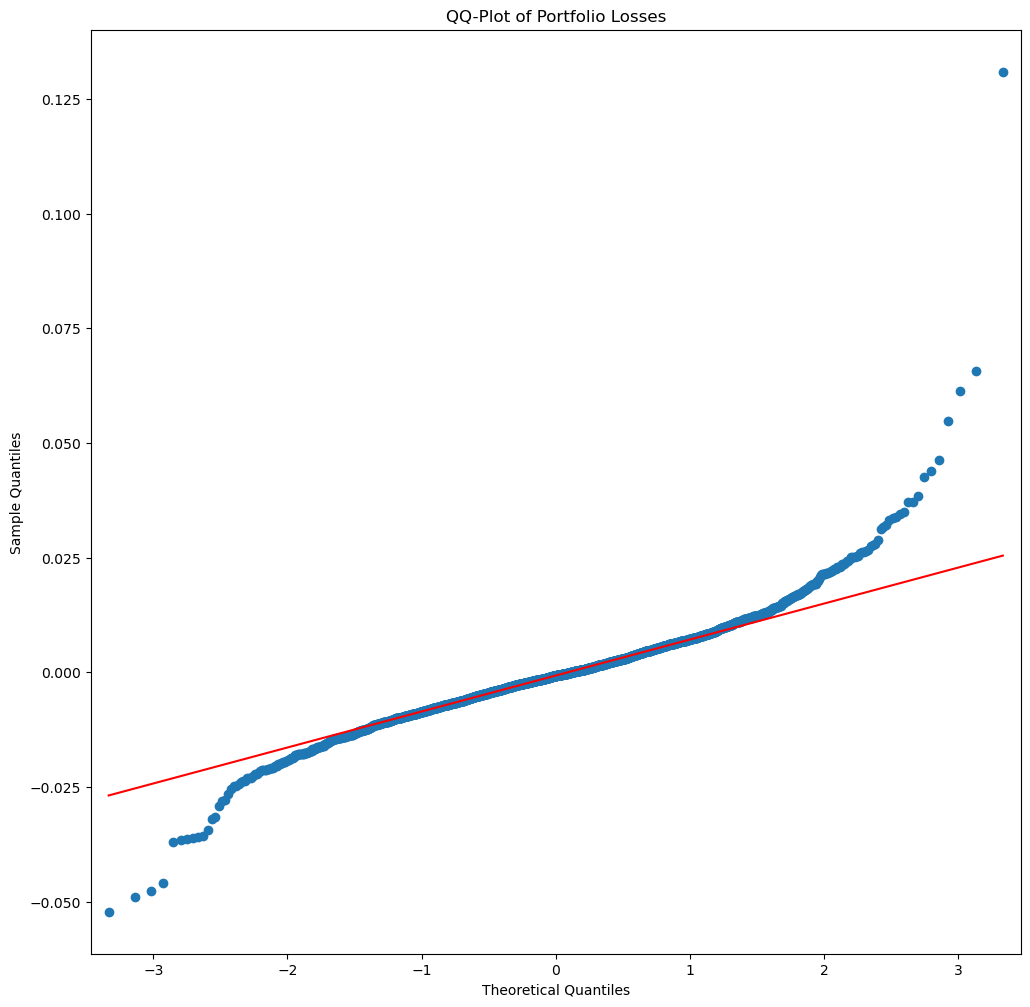

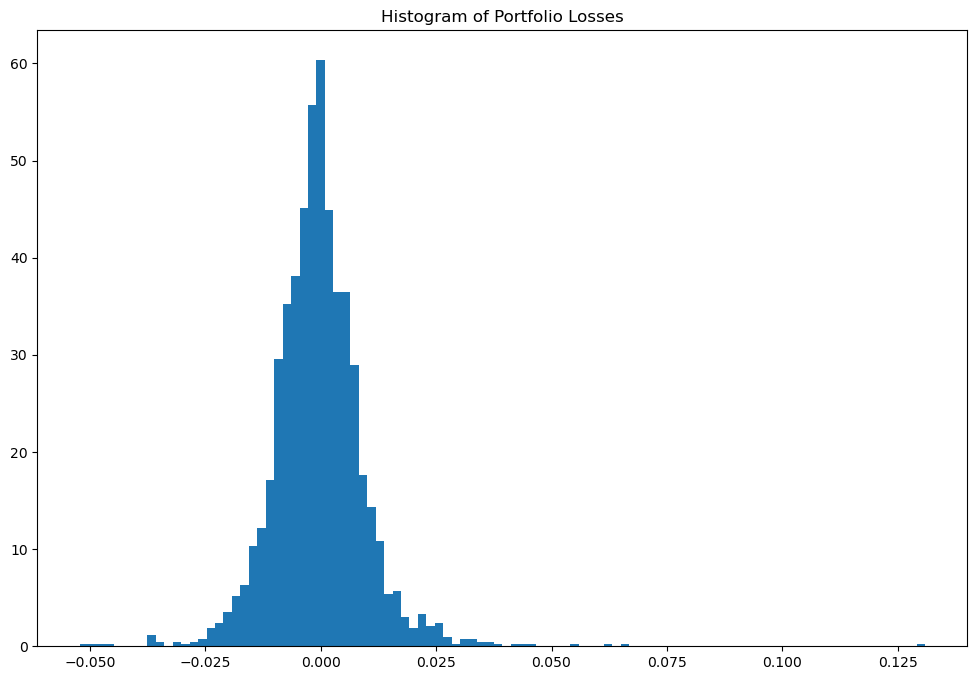

In [144]:
# QQ-Plot and Historgram on Portfolio Level

#QQ-plot
plt.figure(figsize=(12, 12))
plt.title("QQ-Plot of Portfolio Losses")
sm.qqplot(portfolio_weighted, dist=stats.norm, line="q", ax=plt.subplot(1,1,1))
plt.show()

#Histogram
plt.figure(figsize=(12, 8))
plt.hist(portfolio_weighted, bins=100, density=True)
plt.title("Histogram of Portfolio Losses")
plt.show()

### t-Student Distribution Assumption

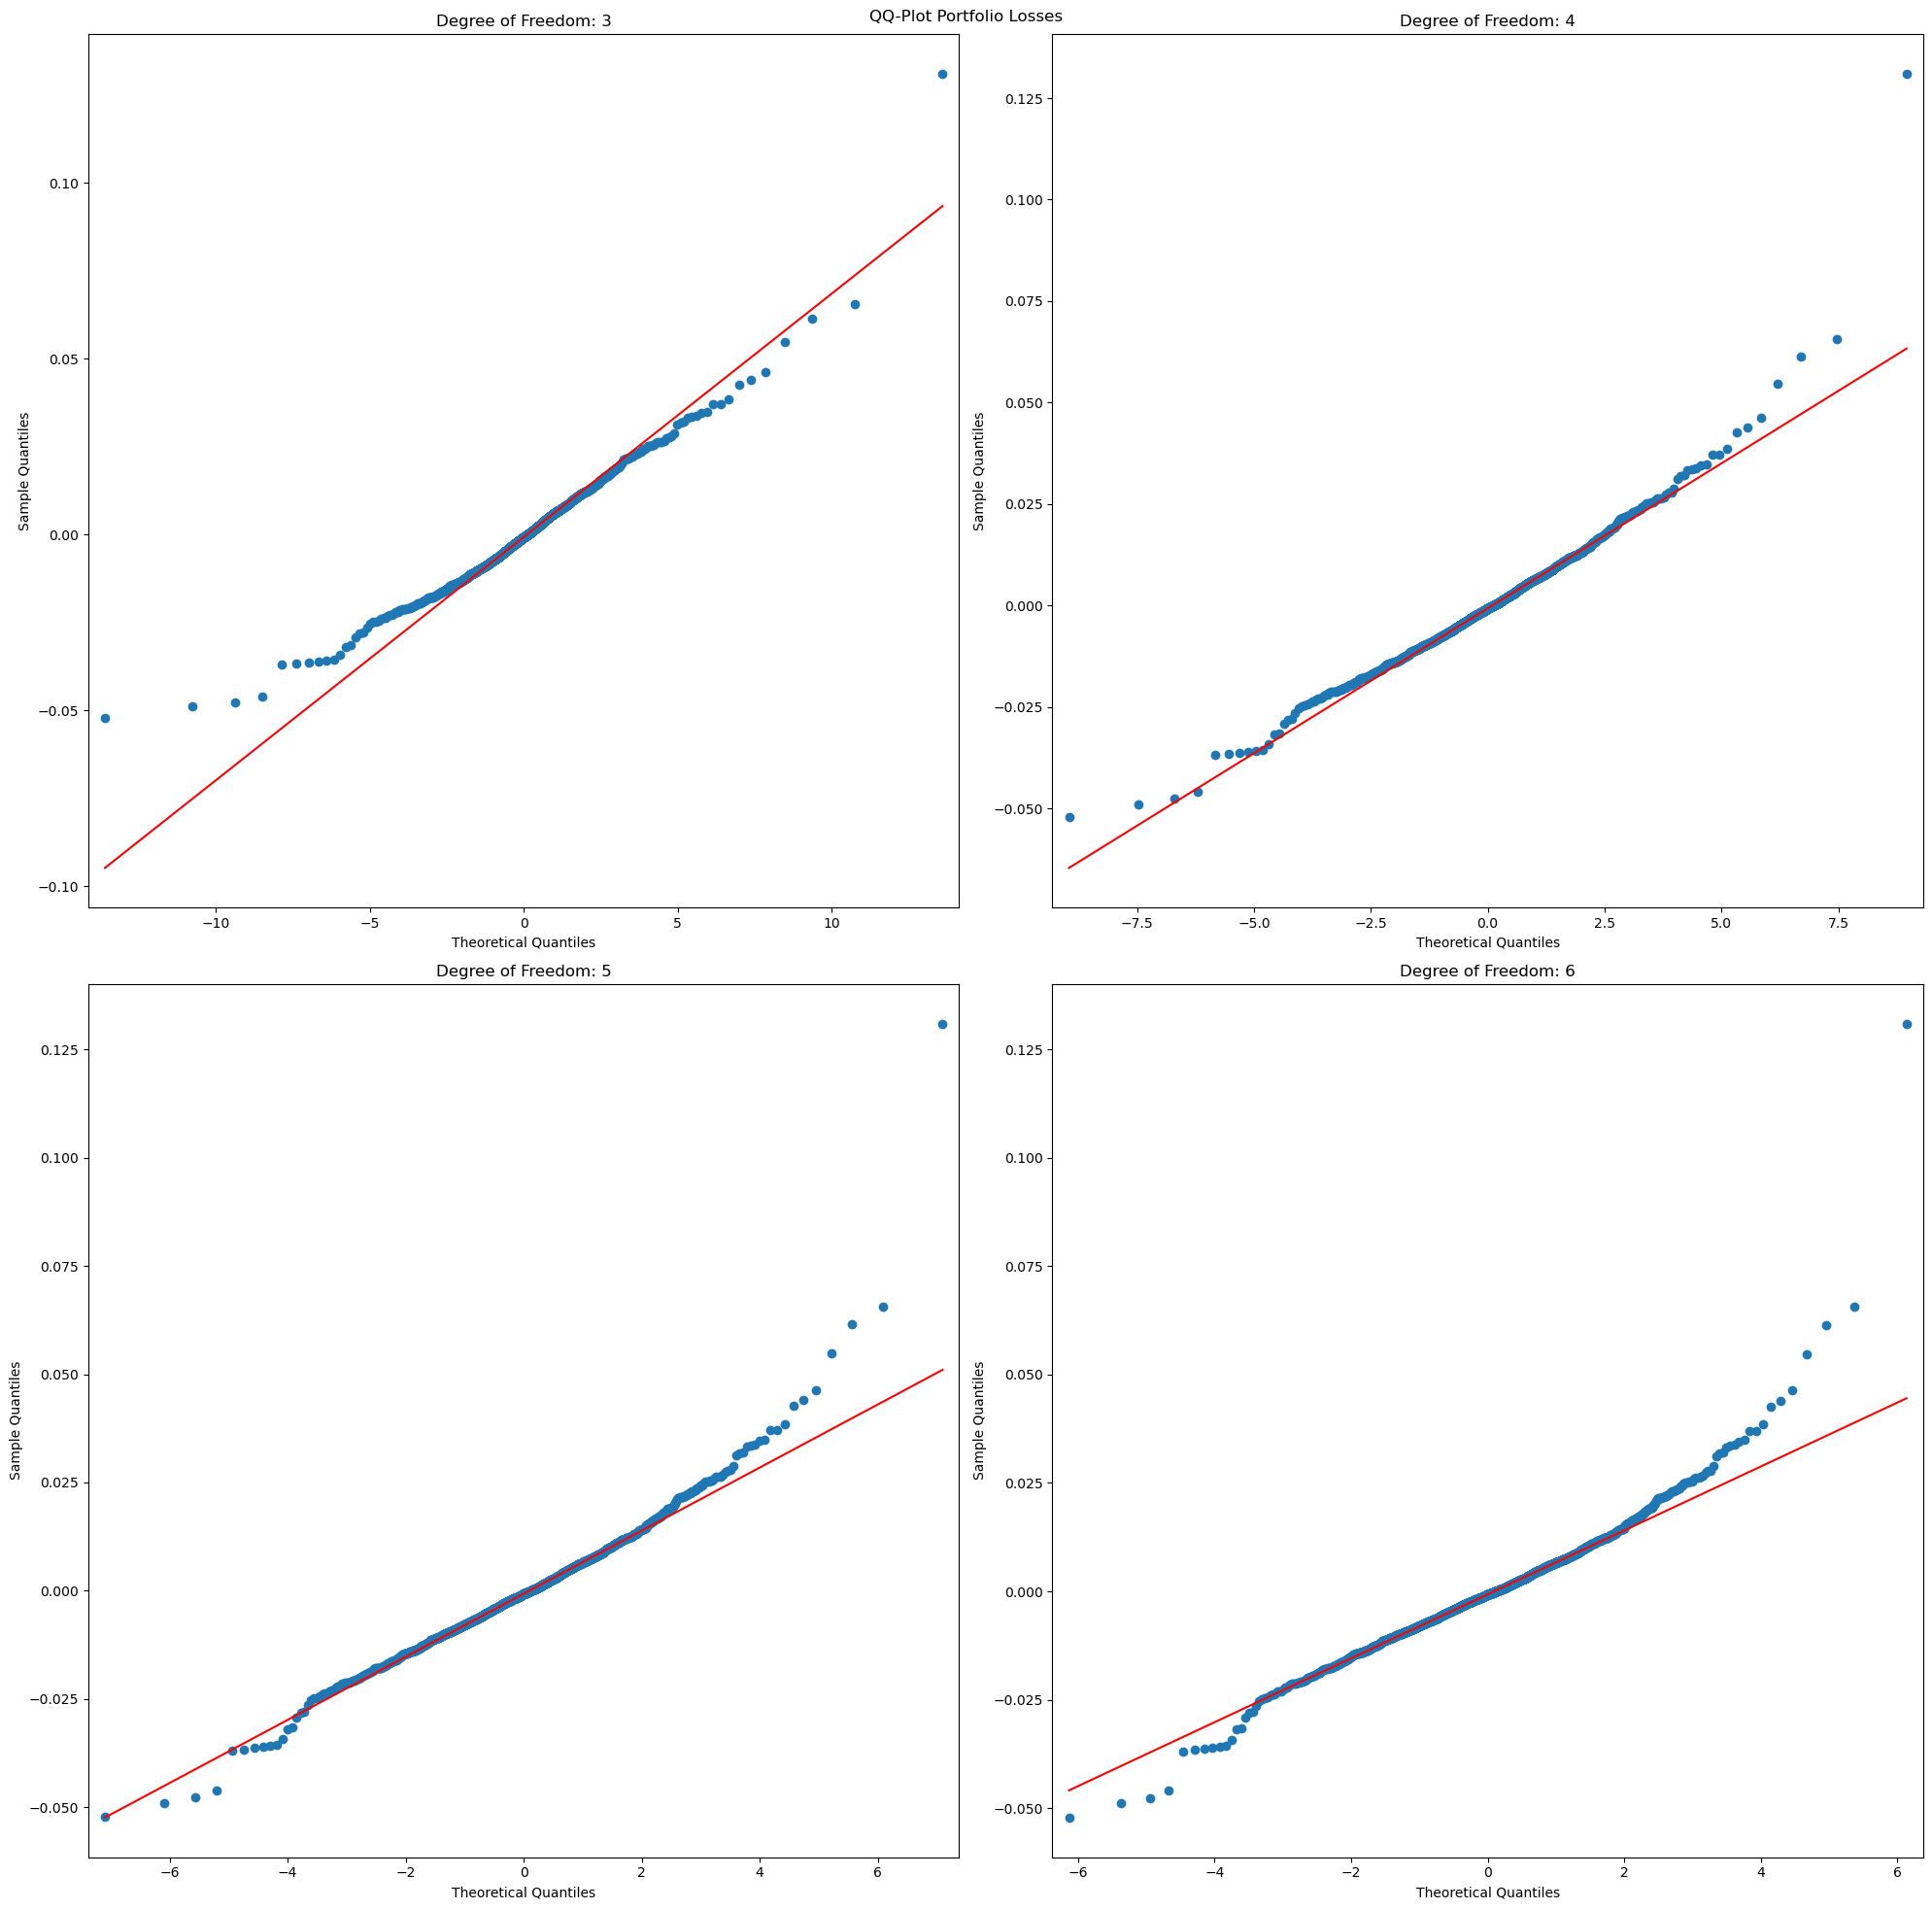

In [145]:
#QQ-plot of historical asset returns to assess validity of Student-t approximation
j = 1
fig = plt.figure(figsize=(20,20))
plt.suptitle("QQ-Plot Portfolio Losses")
degrees_of_freedom = np.array([3, 4, 5, 6])
for d in degrees_of_freedom:
    sm.qqplot(portfolio_weighted, dist=stats.t, distargs=(d,), line="q", ax=plt.subplot(2,2,j))
    plt.subplot(2,2,j).title.set_text('Degree of Freedom: ' + str(d))
    j += 1
plt.tight_layout()
plt.show()

## Backtest

In [146]:
from scipy.stats import norm

# Function to obtain interarrival Rates
def calculate_distances(array):
    
    # Get indices of 1s
    ones_indices = np.where(array == 1)[0]
    
    # Calculate distances between consecutive indices of 1s
    if len(ones_indices) > 1:
        distances = np.diff(ones_indices)
    else:
        distances = []  # If there's only one or no 1 at all, no distances to calculate
    
    return distances

def Backtest(VaR, ES, Loss, alpha, qqplot_arrival=False):
    """
    Perform a t-test to assess the accuracy of the Expected Shortfall (ES) estimation at the confidence level.

    Parameters:
    - VaR: Array of VaR estimates at the 97.5% confidence level.
    - ES: Array of ES estimates at the 97.5% confidence level.
    - Loss: Distribution of Observed Losses.

    """
    # Tests for VaR
    Violations_VaR = Loss > VaR
    N = len(Violations_VaR)

    if qqplot_arrival == True:
        distances = calculate_distances(Violations_VaR)
        # Checking if distances array is not empty
        if len(distances) > 0:
            # Generate a QQ-plot
            plt.figure(figsize=(12, 12))
            sm.qqplot(distances, dist=stats.expon, line="q", ax=plt.subplot(1,1,1))
            plt.title('QQ-Plot: InterArrival Distance vs. Exponential Distribution')
            plt.show()
        else:
            print("Not enough data points (1s) to generate a QQ-plot.")

    print("\nVaR Violations: ", sum(Violations_VaR))
    Z_n = (sum(Violations_VaR) - N*(1-alpha)) / np.sqrt(N*(1-alpha)*alpha) 
    critical_value = norm.ppf(0.05, loc=0, scale=1)        # Using two sided test, so that both Bank and Regulators are happy
    # Check if the provided z-score is beyond the critical value for the normal distr (which approximates the Binomial well)
    if abs(Z_n) > critical_value:
        print("VaR Violations amount differs significantly from Expected\n")

    # Tests for ES
    # As an average quantity it follows normal distribution, thus we can use t test
    average_Real_ES = np.mean(Loss[Violations_VaR])     # Calculate Real World ES (the mean loss where VaR violation occured)
    average_Theoretical_ES = np.mean(ES[Violations_VaR])    # ES obtained with the Prediction Method
    print("Average ES Real and Theoretical: ", average_Real_ES, average_Theoretical_ES)

    # Calculate the two sample z-test to find if they follow different distributions
    standard_error = np.std(Loss[Violations_VaR]) / np.sqrt(np.sum(Violations_VaR))
    # Compute the z-test statistic
    Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
    ES_p = stats.norm.sf(abs(Z_Test_ES)) * 2     # Calculate the two-sided p-value from the t-test statistic
    print("ES t-Test significance of difference: ", ES_p, " | Reject if <0.05\n\n")

    return

In [147]:
# Obtaining Correct windows for Year Sizes

dates = loss_df.index
indexes_year_changes = [0]
for i in range(len(dates)-1):           # Just scanning where date year index changes
    if dates[i+1].year != dates[i].year:
        indexes_year_changes.append(i+1)
indexes_year_changes.append(len(dates)-1)
print("Indexes where year changes: ", indexes_year_changes)

Indexes where year changes:  [0, 258, 516, 774, 1032, 1290, 1549, 1808, 2066, 2323]


In [148]:
# Updating portfolio, we do not need first lines that went into VaR train
portfolio_weighted = loss_df.dot(PORTFOLIO_WEIGHTS)     # PROBABLY WRONG WEIGHTS
portfolio_weighted = portfolio_weighted[indexes_year_changes[1]:]       # Drop lines which are in the burning period for VaR

## .95 VaR and ES

### Normal

In [149]:
# For each period we find amount of VaR violations
alpha = .95
VaR = Var_Cov_VaR(loss_df, window_size = 258, port_weights = PORTFOLIO_WEIGHTS, alpha = alpha, dist = stats.norm.ppf)
ES  = Var_Cov_ES(VaR.Vol, alpha = alpha, dist = stats.norm)
# We need tp cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - 258
    end     = indexes_year_changes[i+1] - 258
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2015+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].VaR.to_numpy(), ES[start:end].to_numpy(), portfolio_weighted[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2016 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  7
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  0.023121987945381273 0.01951949811219104
ES t-Test significance of difference:  0.18469771508592392  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2017 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  13
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  0.01389924374371795 0.013340262308045057
ES t-Test significance of difference:  0.6030819234445092  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2018 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  16
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  0.020196254525031723 0.016729729508693128
E

### Student-t

In [150]:
# Degree 4
alpha = .95
VaR = Var_Cov_VaR(loss_df, window_size = 258, port_weights = PORTFOLIO_WEIGHTS, alpha = alpha, dist = stats.t.ppf, df = 4)
ES  = Var_Cov_ES(VaR.Vol, alpha = alpha, dist = stats.t, df = 4)
# We need tp cover all years one by one, as some of them had different trading days amount
for i in range(1, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i] - 258
    end     = indexes_year_changes[i+1] - 258
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2015+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].VaR.to_numpy(), ES[start:end].to_numpy(), portfolio_weighted[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2016 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  3
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  0.030125117113279268 0.030295566129631493
ES t-Test significance of difference:  0.9595337881629629  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2017 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  4
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  0.01844372261132203 0.020294191026213132
ES t-Test significance of difference:  0.3745889790365471  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2018 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  10
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  0.023313059110653497 0.025672347455585838
ES

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [151]:
# RUN BACKTESTS FOR OTHER METHODS BY THE SAME LOGIC

# Var-Cov with Normal
VaR_HS_normal.VaR
ES_HS_normal
# Var-Cov with Student T
VaR_HS_student4.VaR
VaR_HS_student5.VaR
VaR_HS_student6.VaR
ES_HS_student4
ES_HS_student5
ES_HS_student6
# Historic Simulation
VaR_ES_Historic_Simulation.VaR
VaR_ES_Historic_Simulation.ES
# Filtered Historical Simulation
EWMA_HS.VaR
EWMA_HS.ES
# Garch
VaR_GARCH
ES_GARCH

,0
Date,
2016-01-04,0.023722
2016-01-05,0.024586
2016-01-06,0.024084
2016-01-07,0.023773
2016-01-08,0.024359
...,...
2023-12-22,0.015383
2023-12-26,0.015176
2023-12-27,0.015039
